# BÀI THỰC HÀNH 4: MẠNG NEURAL HỒI QUY

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses.

Bộ dữ liệu sử dụng: [PhoMT](https://drive.google.com/drive/folders/186OAOuSEYEDVcry7WP5UBdqECXo26QAb?usp=drive_link).

In [1]:
!pip install --use-pep517 torch numpy pandas matplotlib rouge-score sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sacrebleu]


In [2]:
# Import thư viện
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU
# Cố định seed và chọn thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.11.0+cu130 | device: cuda


In [3]:
# Cấu hình chung; Phần C đổi các giá trị có chú thích "Phần C"
cfg = dict(
    emb=256, hidden=256, layers=3,  
    dropout=0.3, batch=32, lr=1e-3, teacher_ratio=0.5,
    epochs=10,                     
    max_words=50,                
    vocab_limit=10000,           
    min_freq=2,
    train_limit=None,           
    dev_limit=None,           
)
for k, v in cfg.items():
    print(f'{k:14}= {v}')


emb           = 256
hidden        = 256
layers        = 3
dropout       = 0.3
batch         = 32
lr            = 0.001
teacher_ratio = 0.5
epochs        = 10
max_words     = 50
vocab_limit   = 10000
min_freq      = 2
train_limit   = None
dev_limit     = None


In [4]:
base = Path.cwd()
LAB = base/'Lab4' if (base/'Lab4').is_dir() else base
DATA = LAB/'data'
ART = LAB/'artifacts'
ART.mkdir(parents=True, exist_ok=True)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
print('Dữ liệu:', DATA.name, '| kết quả lưu ở:', ART.name)

Dữ liệu: data | kết quả lưu ở: artifacts


In [5]:
# Tải tệp còn thiếu, rồi kiểm tra SHA-256 của cả ba tệp
DATA_FILES = [{'file': 'small-train.json',
  'url': 'https://drive.google.com/uc?export=download&id=1-eG6FeF-v__rsf77iWurddahXbyjTYh5',
  'sha256': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba'},
 {'file': 'small-dev.json',
  'url': 'https://drive.google.com/uc?export=download&id=1hoTd2hFwjSeFThlPm6YpN0NW5ePXS3Jc',
  'sha256': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9'},
 {'file': 'small-test.json',
  'url': 'https://drive.google.com/uc?export=download&id=1_3L25SH1_jaEfOjpmpgnfMik4N3MxSyn',
  'sha256': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'}]
for item in DATA_FILES:
    path = DATA/item['file']
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(item['url'], timeout=90) as r:
            content = r.read()
        if hashlib.sha256(content).hexdigest() != item['sha256']:
            raise ValueError('Nguồn tải đổi hoặc trả về HTML: '+item['file'])
        path.write_bytes(content)
    if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
        raise ValueError('Checksum không khớp: '+item['file'])
print('3/3 tệp dữ liệu khớp SHA-256.')


3/3 tệp dữ liệu khớp SHA-256.


In [6]:
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

print(tokens('Tôi YÊU bạn'))

['tôi', 'yêu', 'bạn']


In [7]:
# Đọc ba tệp, giữ cặp có cả hai phía dài từ 1 đến max_words token
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    path = DATA/f'small-{split}.json'
    raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(source) <= cfg['max_words'] and \
                1 <= len(target) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    print(split, '| tệp gốc:', len(raw[split]),
          '| sau lọc:', len(filtered[split]))


train | tệp gốc: 20000 | sau lọc: 18607
dev | tệp gốc: 2000 | sau lọc: 1901
test | tệp gốc: 2000 | sau lọc: 1786


In [8]:
assert [len(raw[s]) for s in raw] == [20000, 2000, 2000]
assert all(filtered[s] for s in filtered)
print('Đúng schema và ba bộ chia gốc: PASS')

Đúng schema và ba bộ chia gốc: PASS


In [9]:
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq']
            and t not in SPECIAL][:cfg['vocab_limit']-4]
    return {token: i for i, token in enumerate(SPECIAL+keep)}
# Từ điển tiếng Anh (nguồn) và tiếng Việt (đích)
src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
assert all(src_vocab[t] == tgt_vocab[t] == i
           for i, t in enumerate(SPECIAL))
print('Từ điển Anh/Việt:', len(src_vocab), len(tgt_vocab))
print('Special IDs:', {t: src_vocab[t] for t in SPECIAL})

Từ điển Anh/Việt: 8943 4003
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}


In [10]:
# Đổi token thành id; token chưa có trong từ điển phải thành UNK
def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

In [11]:
# Ghép batch: nguồn thêm EOS, đích thêm BOS/EOS, đệm PAD bên phải
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab)+[EOS]) for r in rows]
    tgt = [torch.tensor([BOS]+encode(r['tgt'], tgt_vocab)+[EOS])
           for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )


In [12]:
toy = [dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
       dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))]
batch = collate(toy)
print('src:', tuple(batch['src'].shape),
      '| lengths:', batch['lengths'].tolist())
print('tgt:', tuple(batch['tgt'].shape))

src: (2, 4) | lengths: [4, 2]
tgt: (2, 5)


In [13]:
# Decoder đọc tgt[:, :-1] để dự đoán tgt[:, 1:] (lệch một bước)
decoder_input = [tgt_itos[i] for i in batch['tgt'][0, :-1].tolist()]
target = [tgt_itos[i] for i in batch['tgt'][0, 1:].tolist()]
print('decoder input:', decoder_input)
print('target       :', target)
assert batch['tgt'][:, :-1].shape == batch['tgt'][:, 1:].shape

decoder input: ['<bos>', 'tôi', 'yêu', 'bạn']
target       : ['tôi', 'yêu', 'bạn', '<eos>']


In [14]:
# Lấy tập con cố định theo seed 42
def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    ids = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in ids]

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
print('Train/dev đang dùng:', len(train_rows), len(dev_rows))
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))
print('Số batch train mỗi epoch:', len(loader(train_rows)))

Train/dev đang dùng: 18607 1901
Số batch train mỗi epoch: 582


In [15]:
# Encoder: Embedding -> LSTM có packing; trả memory và (h, c)
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state
# Chạy thử encoder trên batch tự tạo và xem shape
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
encoder = Encoder(len(src_vocab), **model_cfg).to(device)
memory, (h, c) = encoder(batch['src'].to(device), batch['lengths'])
print('memory:', tuple(memory.shape))
print('h/c:', tuple(h.shape), tuple(c.shape))


memory: (2, 4, 256)
h/c: (3, 2, 256) (3, 2, 256)


In [16]:
# Hai kiểu tính điểm: Bahdanau (cộng) và Luong general (nhân)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + self.Wk(memory))
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory),
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights
# Kiểm tra: trọng số mỗi câu cộng bằng 1 và bằng 0 tại vị trí PAD
mask = batch['src'].to(device) != PAD
for mode in ['bahdanau', 'luong']:
    attn = Attention(cfg['hidden'], mode).to(device)
    context, weights = attn(h[-1], memory, mask)
    ones = torch.ones(len(toy), device=device)
    assert torch.allclose(weights.sum(-1), ones)
    assert torch.all(weights.masked_select(~mask) == 0)
    print(mode, '| context:', tuple(context.shape), '| mask: PASS')

bahdanau | context: (2, 256) | mask: PASS
luong | context: (2, 256) | mask: PASS


In [17]:
# Decoder chạy từng bước; mode = 'none', 'bahdanau' hoặc 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights
for mode in ['none', 'bahdanau', 'luong']:
    decoder = Decoder(len(tgt_vocab), mode, **model_cfg)
    print(f'{mode:9}| tham số decoder:',
          sum(p.numel() for p in decoder.parameters()))

none     | tham số decoder: 3632547
bahdanau | tham số decoder: 4157347
luong    | tham số decoder: 4091555


In [18]:
# Seq2Seq = Encoder + Decoder; teacher_ratio là xác suất dùng token đúng
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)
# Kiểm tra shape logits của ba mô hình
def make_seq2seq(mode, **kwargs):
    kwargs = kwargs or model_cfg
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kwargs).to(device)

for mode in ['none', 'bahdanau', 'luong']:
    seed_all()
    model = make_seq2seq(mode)
    logits = model(batch['src'].to(device), batch['lengths'],
                   batch['tgt'].to(device), teacher_ratio=1.0)
    assert logits.shape[:2] == batch['tgt'][:, 1:].shape
    print(mode, '| logits:', tuple(logits.shape))

none | logits: (2, 4, 4003)
bahdanau | logits: (2, 4, 4003)
luong | logits: (2, 4, 4003)


In [19]:
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights
# Đổi dãy id thành câu, dừng ở EOS và bỏ PAD/BOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)


In [20]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD)


In [21]:
# ROUGE-L với tokenizer giữ dấu tiếng Việt, không stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())


In [22]:
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score, bleu_signature=str(bleu.get_signature()))


In [23]:
@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hypotheses, references = [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        target = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)), target.reshape(-1),
            ignore_index=PAD, reduction='sum').item()
        count += int((target != PAD).sum())
        generated, _ = generate(model, src, b['lengths'], cfg['max_words']+1)
        hypotheses.extend(decode(row) for row in generated.cpu())
        references.extend(b['refs'])
    metrics = translation_metrics(hypotheses, references)
    metrics['dev_nll'] = nll/count
    return metrics,hypotheses,references


In [24]:
# Huấn luyện một epoch, trả loss trung bình trên token thật
def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)),
                         gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        loss_total += loss.item()*n
        tokens_total += n
    return loss_total/tokens_total
# Vòng huấn luyện: mỗi epoch train rồi chấm dev, giữ checkpoint tốt nhất
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1., float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs']+1):
        seed_all(42+epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter()-start
        measured,_,_ = evaluate(model, dev_rows)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss,
                            seconds=seconds, **measured))
        print(f"{name} epoch {epoch}: loss={train_loss:.4f} "
              f"dev_ROUGE-L={measured['rougeL_f1']:.4f} "
              f"BLEU={measured['bleu']:.2f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART/f'{name}.pt')
    return history, best_epoch


#### Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

In [26]:
# Khởi tạo Seq2Seq không attention
models, histories, best_epochs = {}, {}, {}
seed_all()
model = make_seq2seq('none')
# Huấn luyện và giữ checkpoint có ROUGE-L dev tốt nhất
histories['none'], best_epochs['none'] = fit(model, 'none')
models['none'] = model


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 1: loss=6.0257 dev_ROUGE-L=0.1280 BLEU=0.06


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 2: loss=5.7262 dev_ROUGE-L=0.1561 BLEU=0.54


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 3: loss=5.5368 dev_ROUGE-L=0.1902 BLEU=1.18


... (10 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 9: loss=4.9619 dev_ROUGE-L=0.2267 BLEU=2.16


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 10: loss=4.9011 dev_ROUGE-L=0.2298 BLEU=2.34


#### Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

In [27]:
# Khởi tạo Seq2Seq + Bahdanau attention
seed_all()
model = make_seq2seq('bahdanau')
# Huấn luyện với cùng cấu hình như mô hình không attention
histories['bahdanau'], best_epochs['bahdanau'] = fit(model, 'bahdanau')
models['bahdanau'] = model


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 1: loss=6.0413 dev_ROUGE-L=0.1413 BLEU=0.17


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 2: loss=5.6456 dev_ROUGE-L=0.1985 BLEU=1.17


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 3: loss=5.3636 dev_ROUGE-L=0.2175 BLEU=1.64


... (10 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 9: loss=4.5577 dev_ROUGE-L=0.2948 BLEU=4.48


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 10: loss=4.4777 dev_ROUGE-L=0.2975 BLEU=4.56


#### Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

In [29]:
# Khởi tạo Seq2Seq + Luong attention 
model = make_seq2seq('luong')
seed_all()
histories['luong'], best_epochs['luong'] = fit(model, 'luong')
models['luong'] = model


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 1: loss=6.0599 dev_ROUGE-L=0.1339 BLEU=0.12


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 2: loss=5.7183 dev_ROUGE-L=0.1787 BLEU=0.89


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 3: loss=5.4633 dev_ROUGE-L=0.1955 BLEU=1.35


... (10 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 9: loss=4.6234 dev_ROUGE-L=0.2873 BLEU=4.19


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 10: loss=4.5364 dev_ROUGE-L=0.2939 BLEU=4.59


In [30]:
# Bảng so sánh ba mô hình trên dev
rows = []
for name, model in models.items():
    score,_,_ = evaluate(model, dev_rows)
    seconds = np.mean([r['seconds'] for r in histories[name]])
    rows.append(dict(model=name, dev_rougeL=score['rougeL_f1'],
                     dev_bleu=score['bleu'], best_epoch=best_epochs[name],
                     parameters=sum(p.numel() for p in model.parameters()),
                     seconds_per_epoch=seconds))
comparison = pd.DataFrame(rows)
comparison.to_csv(ART/'comparison_dev.csv', index=False)
table = comparison.round(4)
print(table.to_string(index=False))


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


   model  dev_rougeL  dev_bleu  best_epoch  parameters  seconds_per_epoch
    none      0.2298    2.3399          10     7500963            64.3273
bahdanau      0.2975    4.5558          10     8025763           101.7083
   luong      0.2939    4.5916          10     7959971            94.3406


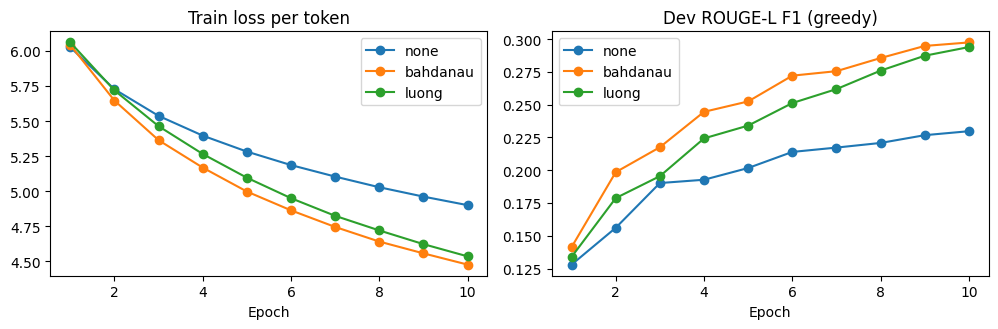

In [31]:
# Vẽ loss train và ROUGE-L dev theo epoch
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, records in histories.items():
    h = pd.DataFrame(records)
    axes[0].plot(h.epoch, h.train_loss, marker='o', label=name)
    axes[1].plot(h.epoch, h.rougeL_f1, marker='o', label=name)
titles = ['Train loss per token', 'Dev ROUGE-L F1 (greedy)']
for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
fig.tight_layout()
fig.savefig(ART/'learning_curves.png', dpi=150)
plt.show()


In [34]:
# Lưu cấu hình, từ điển và id các cặp đã dùng vào metadata.json
metadata = dict(config=cfg, seed=42, device=str(device),
                normalization='NFC; remove BOM; lowercase; whitespace',
                src_vocab=src_vocab, tgt_vocab=tgt_vocab, files=DATA_FILES,
                selected_train_ids=[r['id'] for r in train_rows],
                selected_dev_ids=[r['id'] for r in dev_rows],
                histories=histories, best_epochs=best_epochs)
text = json.dumps(metadata, ensure_ascii=False, indent=2)
(ART/'metadata.json').write_text(text, encoding='utf-8')
print('Đã lưu metadata.json và', len(models), 'checkpoint .pt')
# Nạp lại checkpoint Bahdanau và so logits với mô hình đang có
restored = make_seq2seq('bahdanau')
state = torch.load(ART/'bahdanau.pt', map_location=device, weights_only=True)
restored.load_state_dict(state)
restored.eval()
b = collate(toy)
with torch.no_grad():
    args = (b['src'].to(device), b['lengths'], b['tgt'].to(device))
    a = restored(*args, teacher_ratio=1.0)
    c = models['bahdanau'](*args, teacher_ratio=1.0)
torch.testing.assert_close(a, c)
print('Nạp lại checkpoint, từ điển và metadata: PASS')


Đã lưu metadata.json và 3 checkpoint .pt
Nạp lại checkpoint, từ điển và metadata: PASS


In [65]:
# ROUGE-L trên toàn bộ test sau lọc của ba mô hình đã chọn
results,test_data = [],[]
for name, model in models.items():
    score,hypotheses,references = evaluate(model, filtered['test'])
    score.pop('dev_nll')
    results.append(dict(model=name, **score))
    test_data.append([hypotheses,references])
results = pd.DataFrame(results)
results.to_csv(ART/'comparison_test.csv', index=False)
print(results.drop(columns='bleu_signature').round(4).to_string(index=False))


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


   model  rougeL_f1  rougeL_precision  rougeL_recall   bleu
    none     0.2346            0.2608         0.2161 2.6148
bahdanau     0.3138            0.3403         0.2957 5.8295
   luong     0.3084            0.3377         0.2877 5.5054


Ba câu mẫu và heatmap cho model Bài 1
Original sentence: ['on', 'july', '20', ',', '2017', ',', 'the', 'permanent', 'council', 'of', 'the', 'osce', 'adopted', 'a', 'statement', 'from', 'the', 'european', 'union', '(', 'eu', ')', '.']
Actual translation: ['ngày', '20-7-2017', ',', 'hội', 'đồng', 'thường', 'trực', 'của', 'osce', 'áp', 'dụng', 'lời', 'nhận', 'xét', 'của', 'liên', 'minh', 'châu', 'âu', '(', 'eu', ')', '.']
Generated translation: những thống này này đã được được một


Original sentence: ['local', 'elders', 'and', 'the', 'circuit', 'overseer', 'are', 'offering', 'practical', 'and', 'spiritual', 'support', 'to', 'those', 'affected', 'by', 'this', 'disaster', '.']
Actual translation: ['các', 'trưởng', 'lão', 'địa', 'phương', 'và', 'giám', 'thị', 'xung', 'quanh', 'đang', 'giúp', 'đỡ', 'và', 'cung', 'cấp', 'về', 'vật', 'chất', 'và', 'tinh', 'thần', 'cho', 'các', 'anh', 'chị', 'bị', 'ảnh', 'hưởng', 'trong', 'thảm', 'hoạ', 'này', '.']
Generated translation: các công nghiệp của các

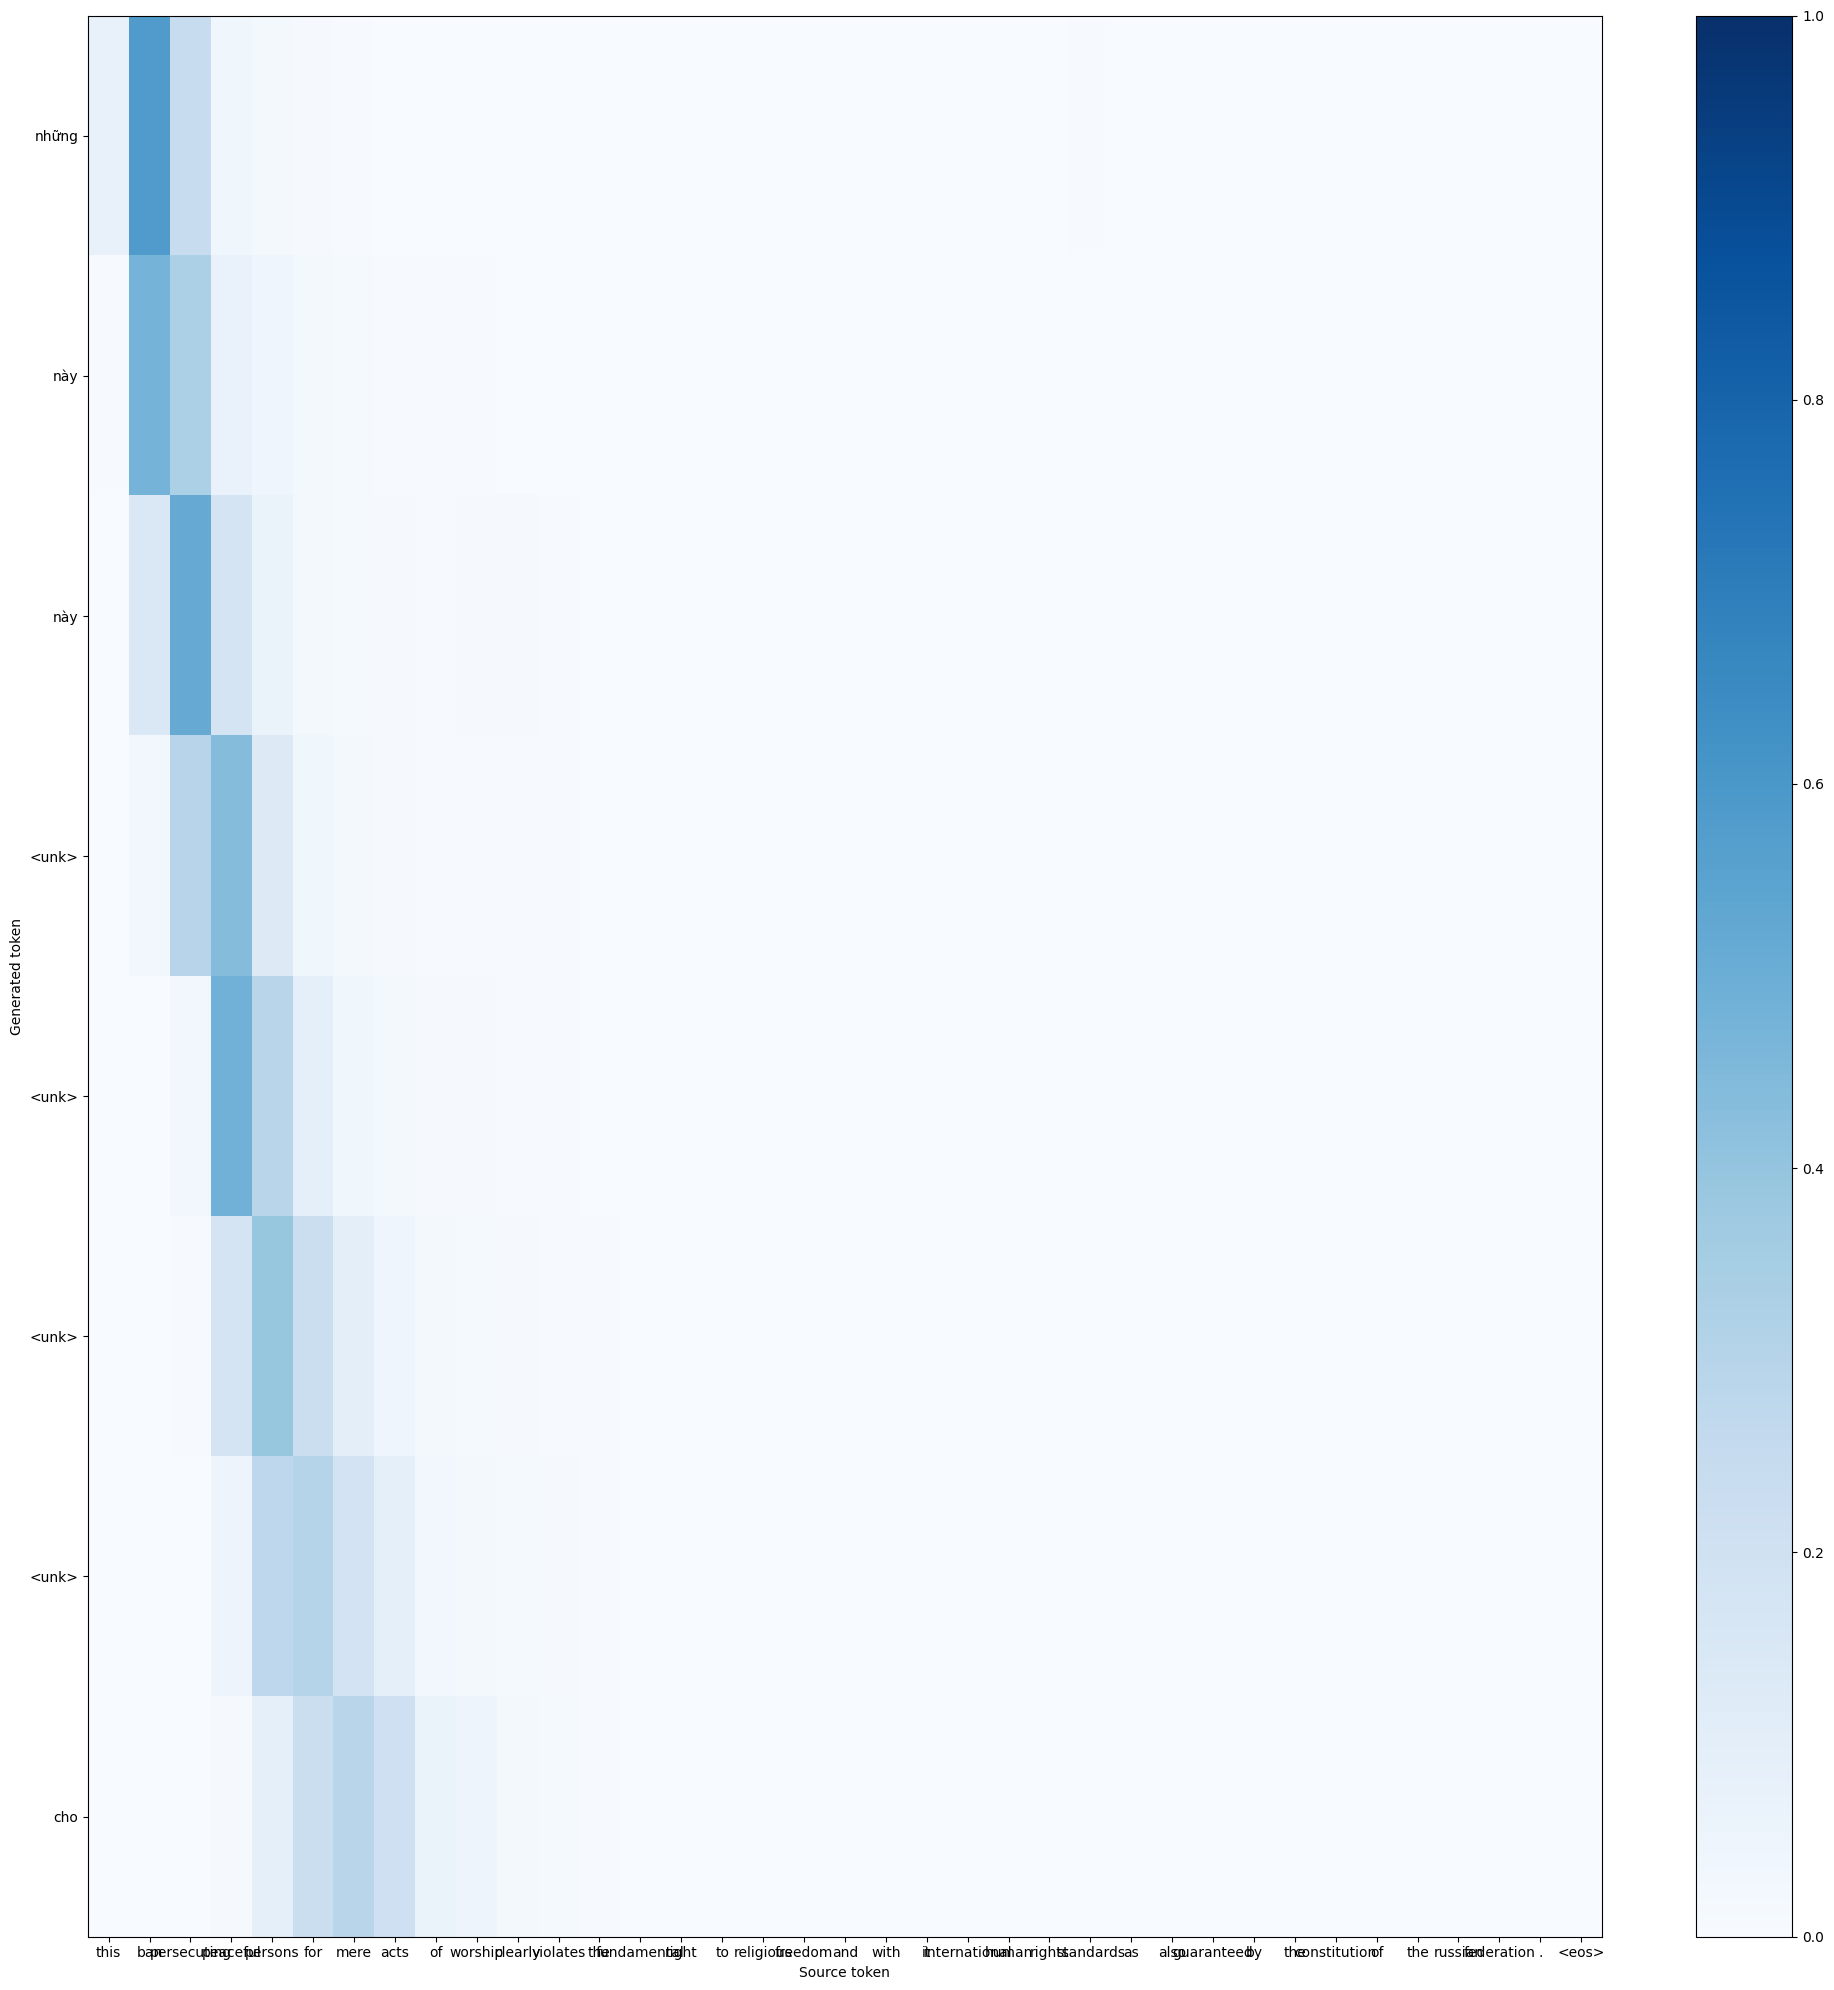



Original sentence: ['local', 'elders', 'and', 'the', 'circuit', 'overseer', 'are', 'offering', 'practical', 'and', 'spiritual', 'support', 'to', 'those', 'affected', 'by', 'this', 'disaster', '.']
Actual translation: ['các', 'trưởng', 'lão', 'địa', 'phương', 'và', 'giám', 'thị', 'xung', 'quanh', 'đang', 'giúp', 'đỡ', 'và', 'cung', 'cấp', 'về', 'vật', 'chất', 'và', 'tinh', 'thần', 'cho', 'các', 'anh', 'chị', 'bị', 'ảnh', 'hưởng', 'trong', 'thảm', 'hoạ', 'này', '.']
Generated translation: các quốc gia và và và và và


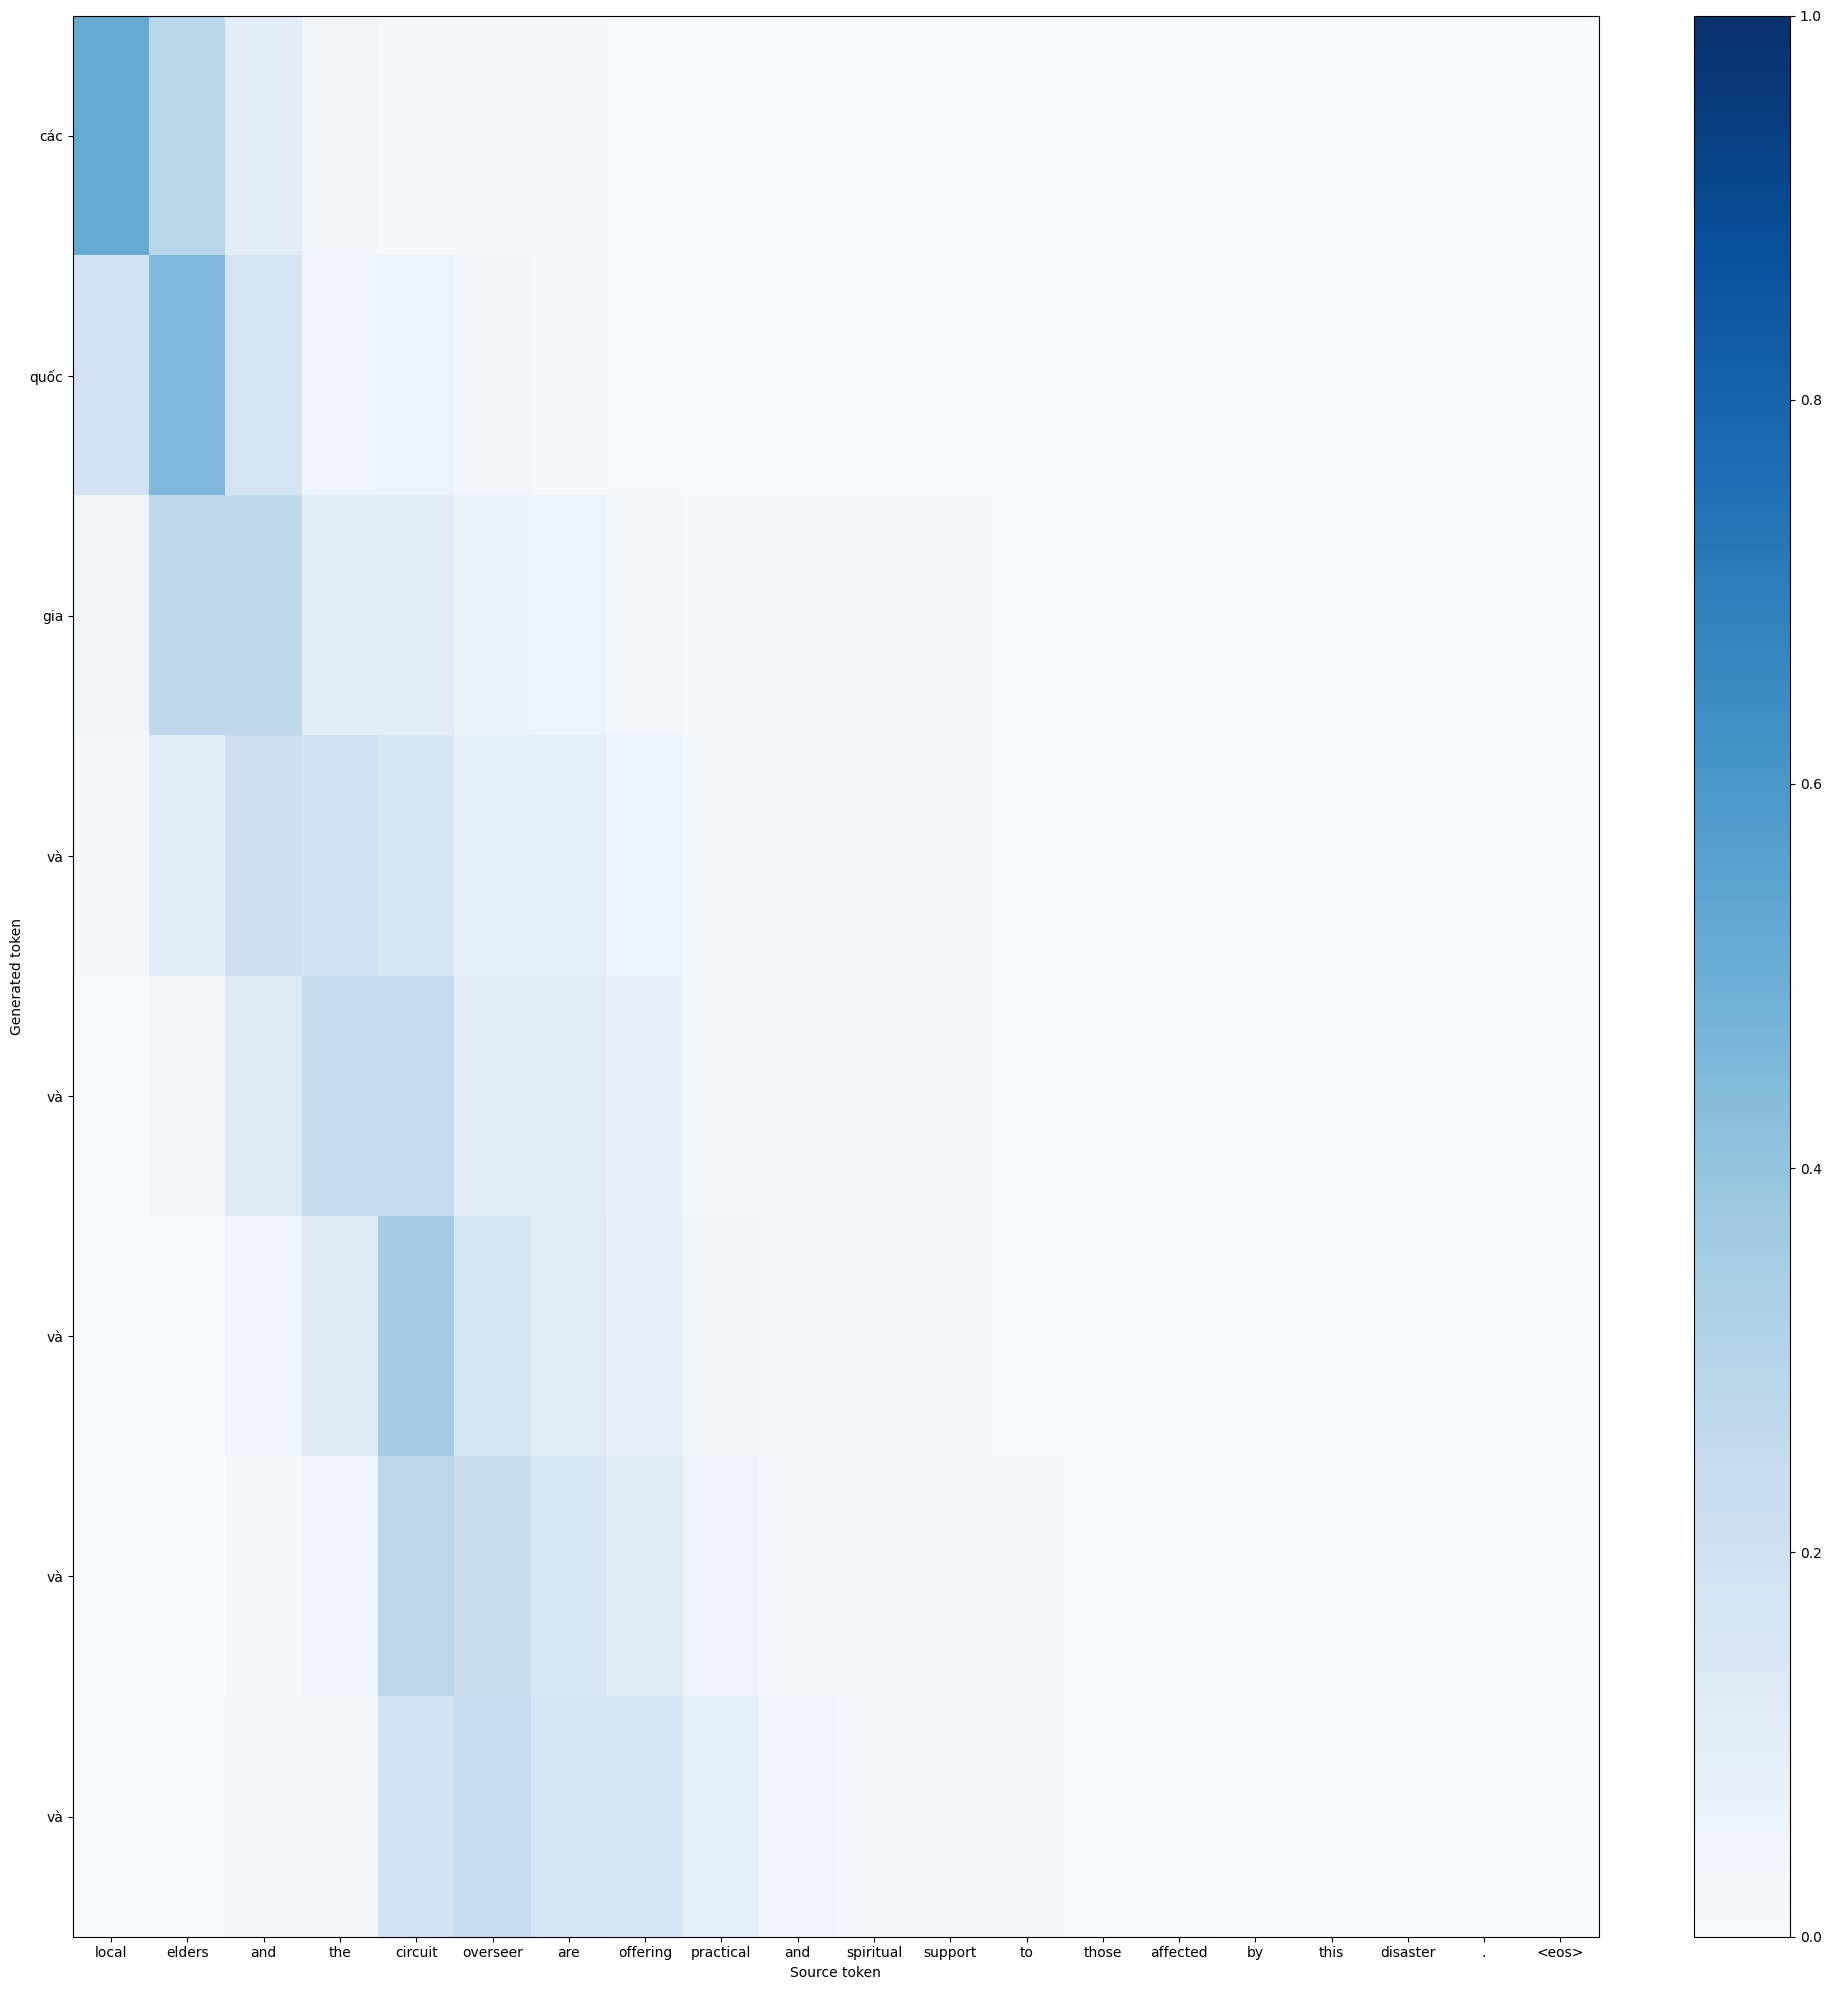



Original sentence: i love you
Actual translation: tôi yêu bạn
Generated translation: tôi yêu bạn .


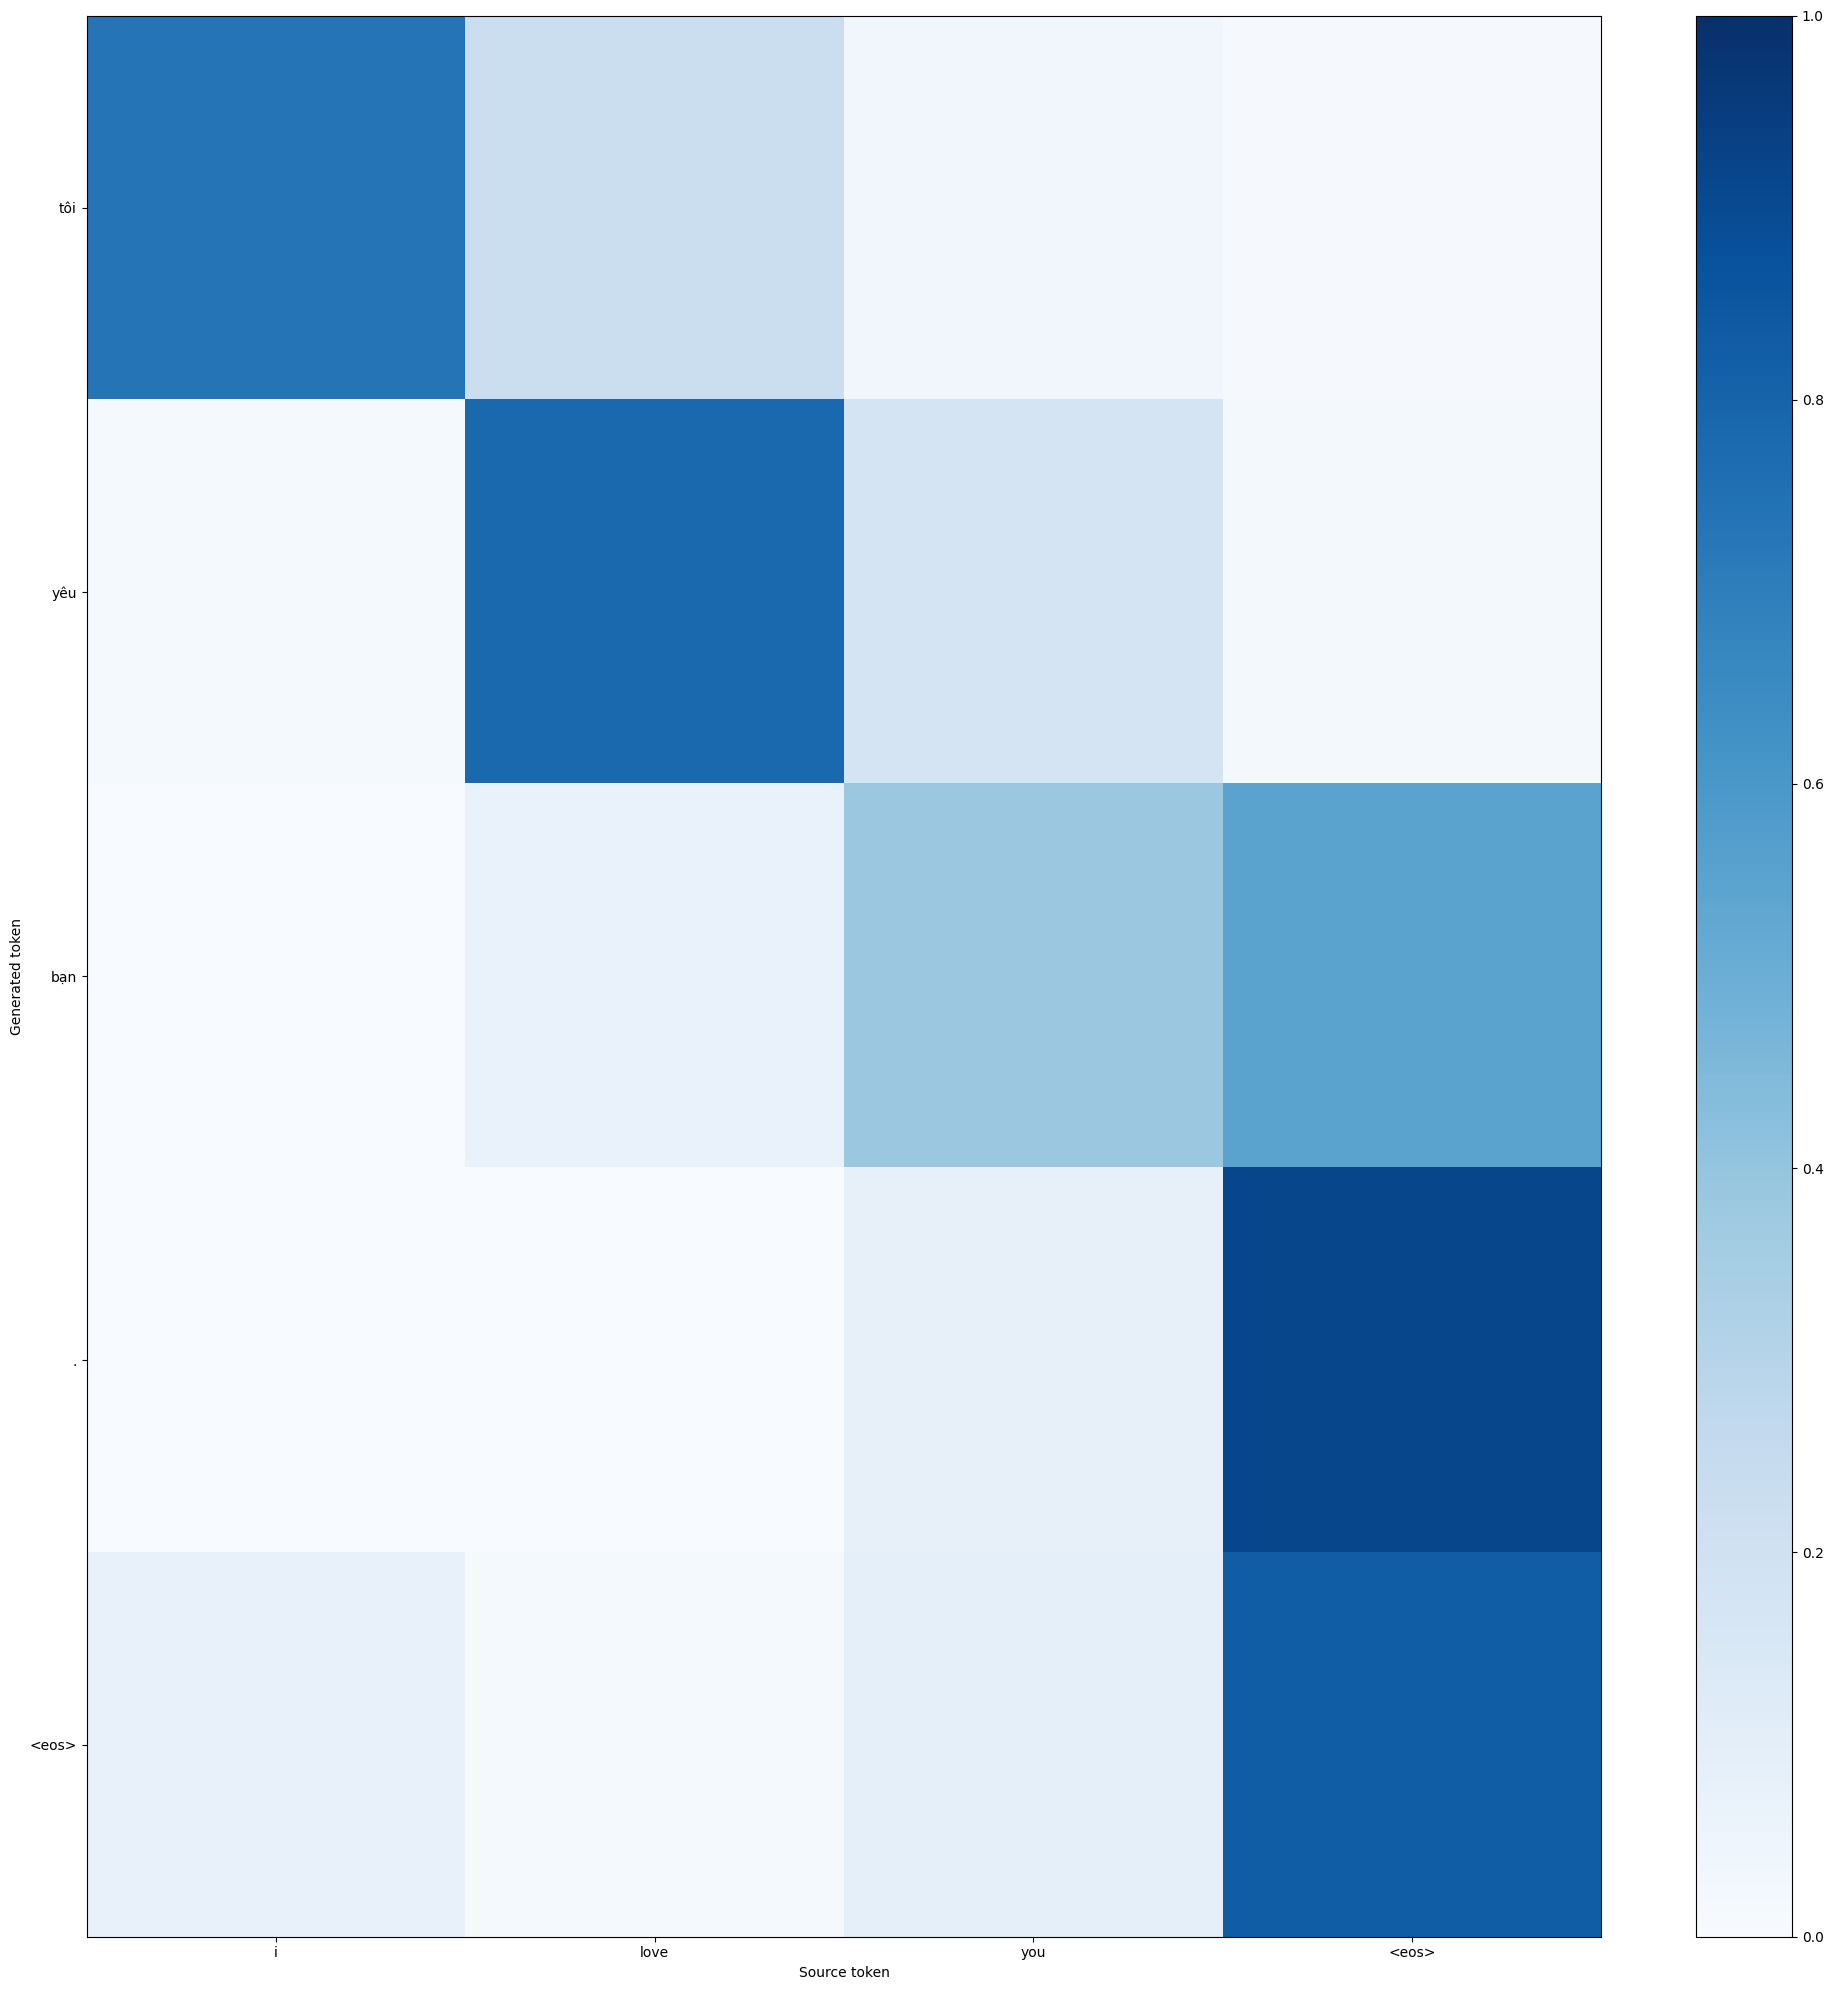




 
 

Ba câu mẫu và heatmap cho model Bài 3
Original sentence: ['on', 'july', '20', ',', '2017', ',', 'the', 'permanent', 'council', 'of', 'the', 'osce', 'adopted', 'a', 'statement', 'from', 'the', 'european', 'union', '(', 'eu', ')', '.']
Actual translation: ['ngày', '20-7-2017', ',', 'hội', 'đồng', 'thường', 'trực', 'của', 'osce', 'áp', 'dụng', 'lời', 'nhận', 'xét', 'của', 'liên', 'minh', 'châu', 'âu', '(', 'eu', ')', '.']
Generated translation: những này này <unk> <unk> <unk> <unk> <unk>


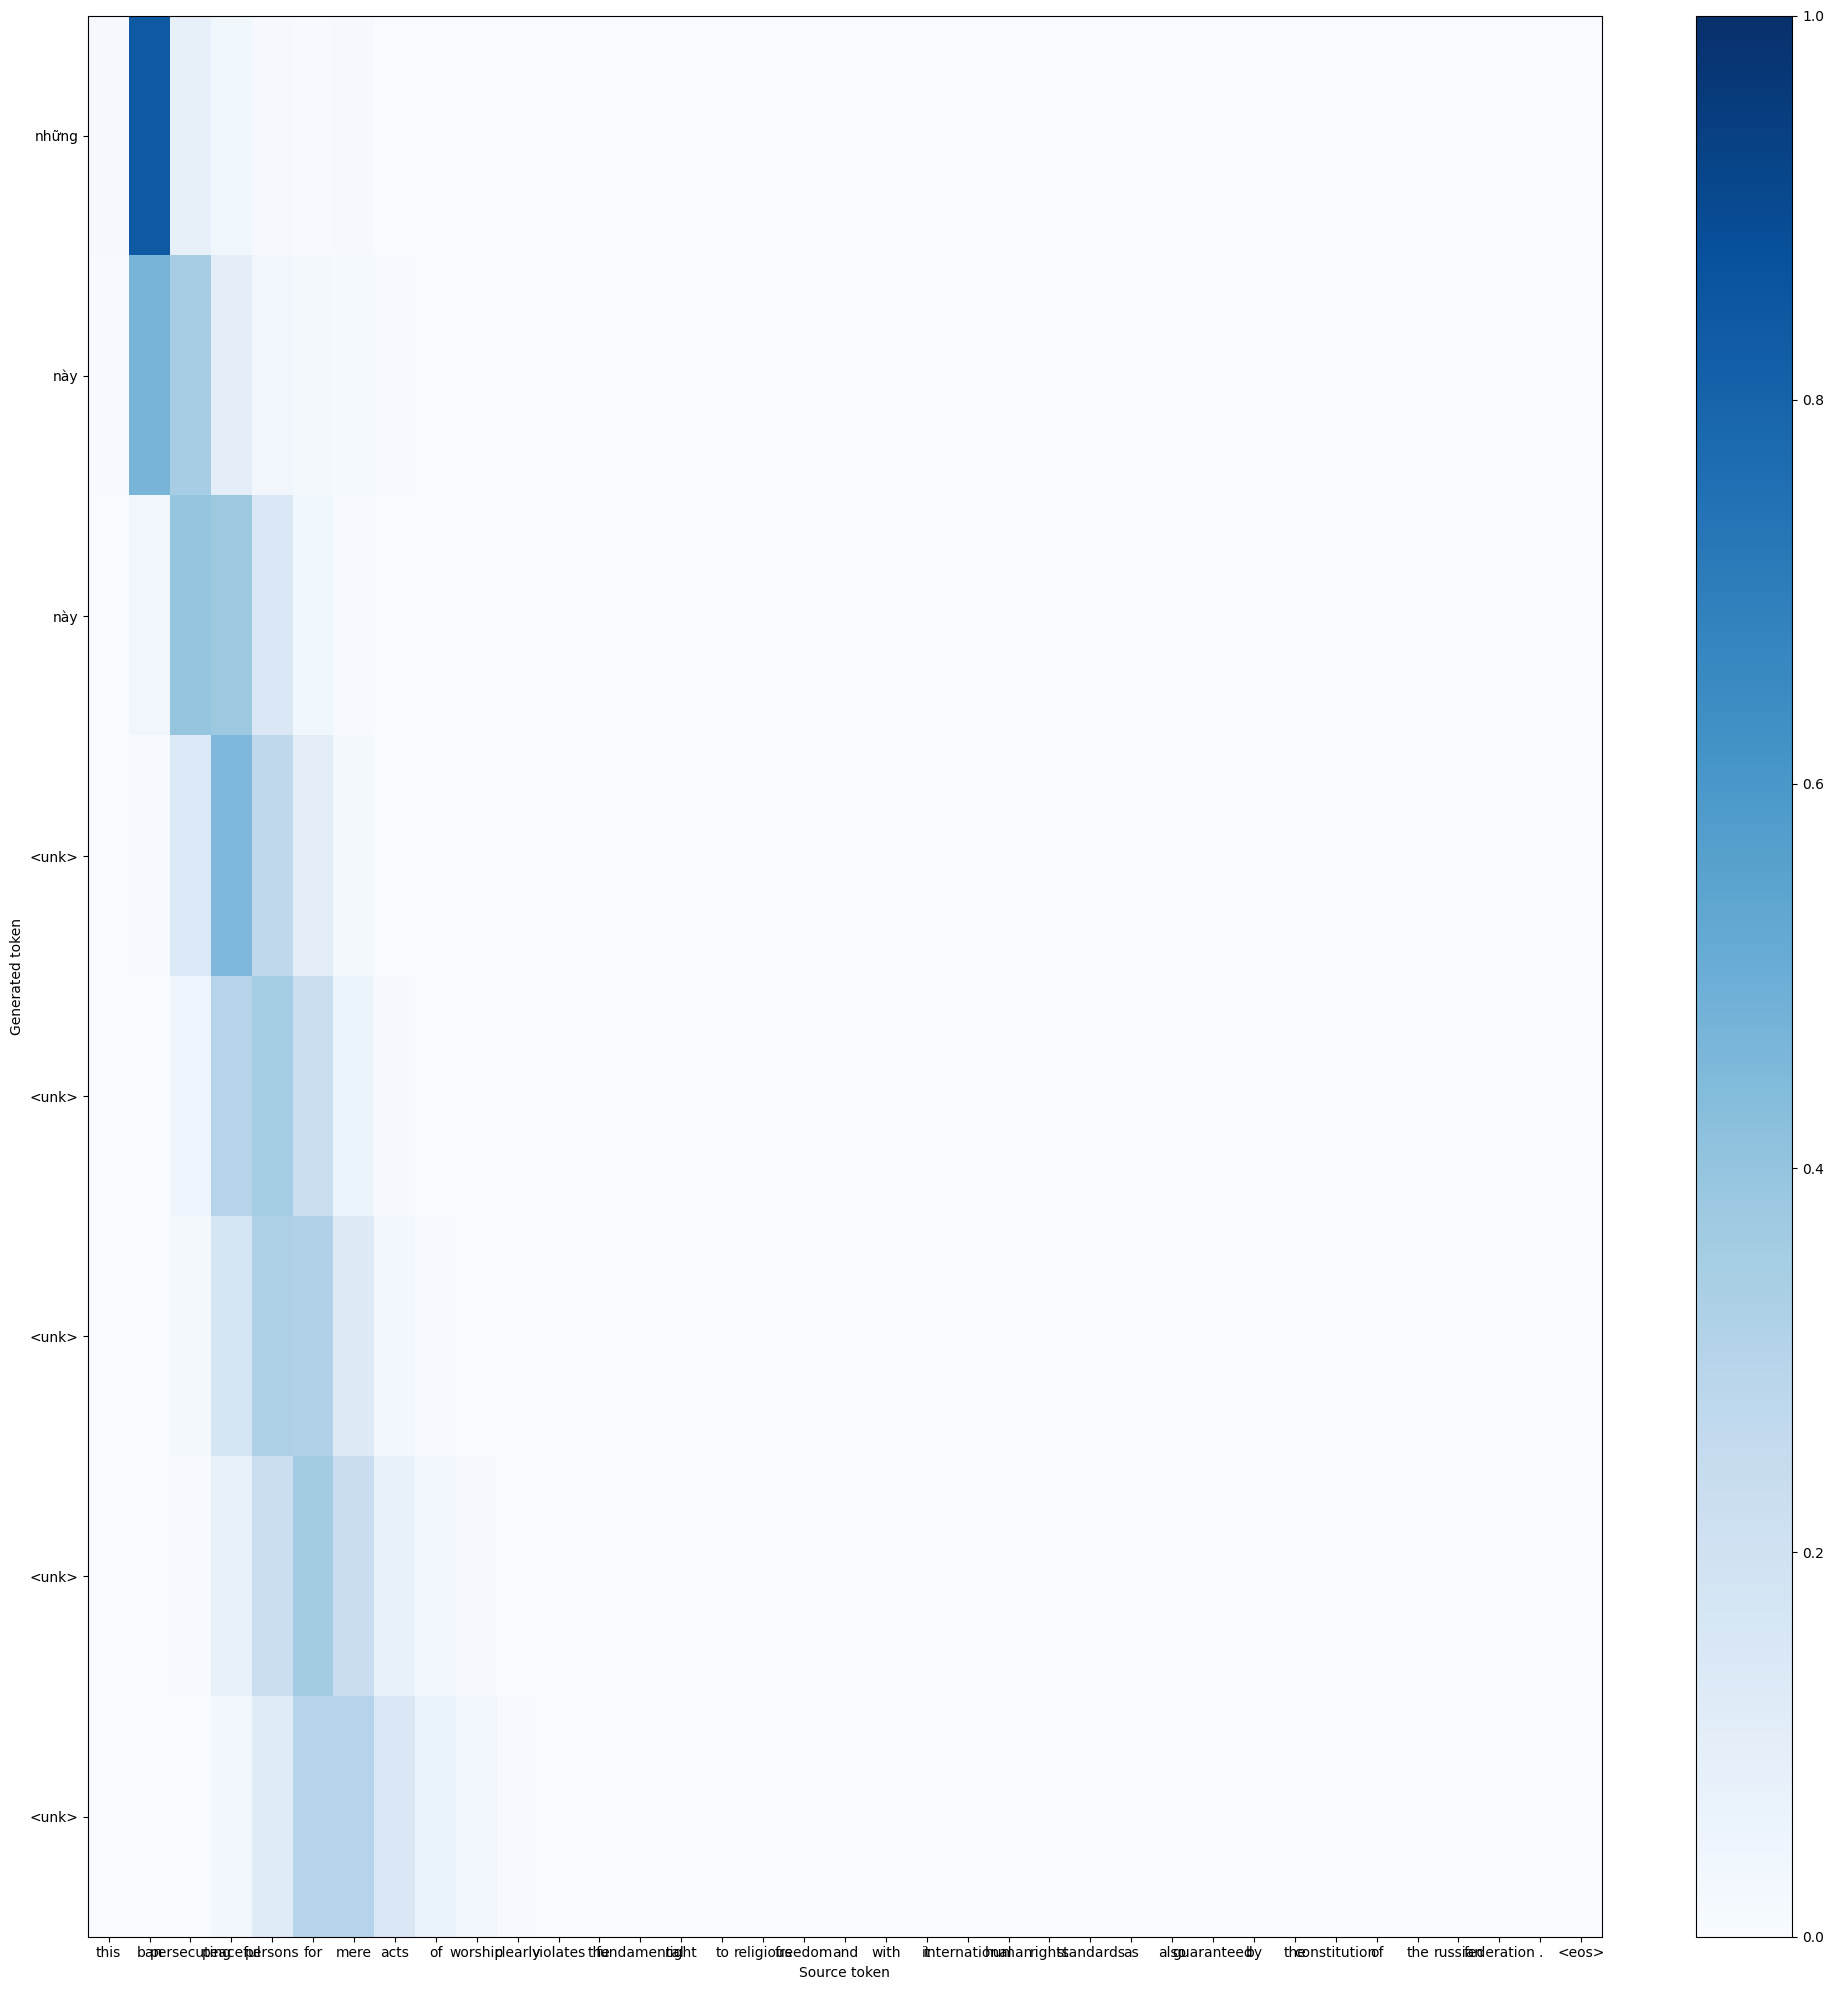



Original sentence: ['local', 'elders', 'and', 'the', 'circuit', 'overseer', 'are', 'offering', 'practical', 'and', 'spiritual', 'support', 'to', 'those', 'affected', 'by', 'this', 'disaster', '.']
Actual translation: ['các', 'trưởng', 'lão', 'địa', 'phương', 'và', 'giám', 'thị', 'xung', 'quanh', 'đang', 'giúp', 'đỡ', 'và', 'cung', 'cấp', 'về', 'vật', 'chất', 'và', 'tinh', 'thần', 'cho', 'các', 'anh', 'chị', 'bị', 'ảnh', 'hưởng', 'trong', 'thảm', 'hoạ', 'này', '.']
Generated translation: các nhà thống và và và và và


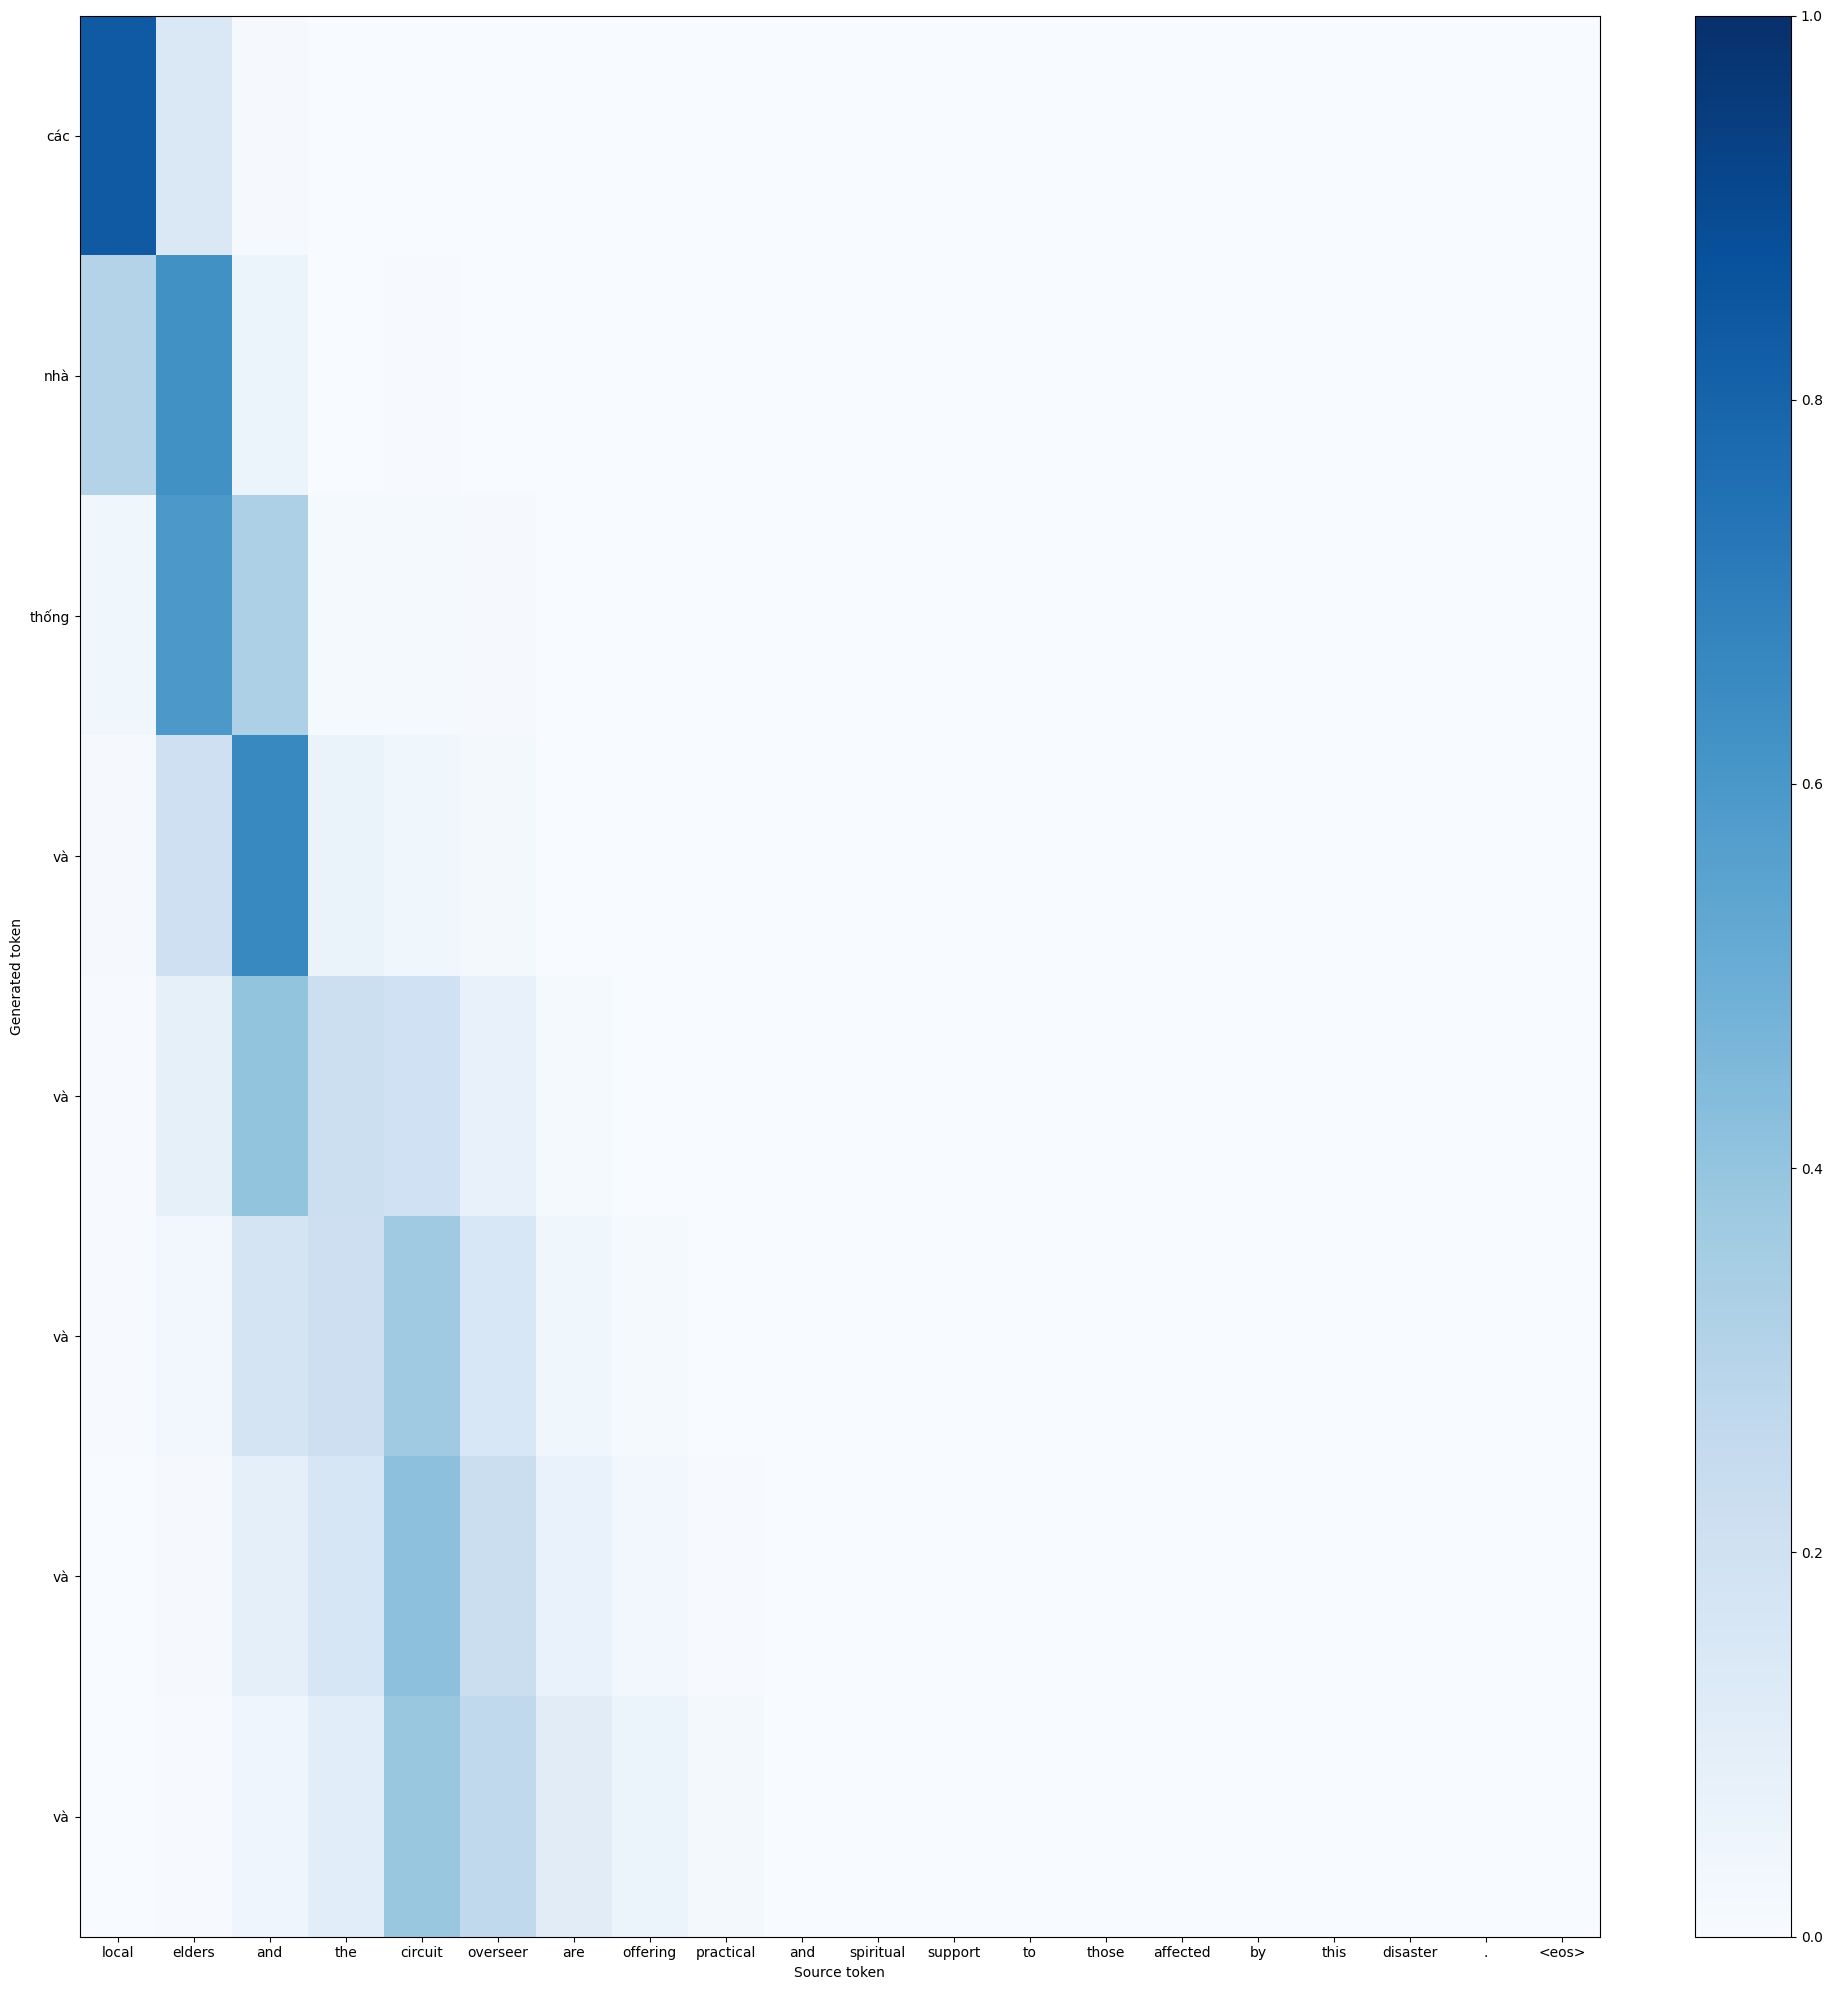



Original sentence: i love you
Actual translation: tôi yêu bạn
Generated translation: tôi yêu bạn


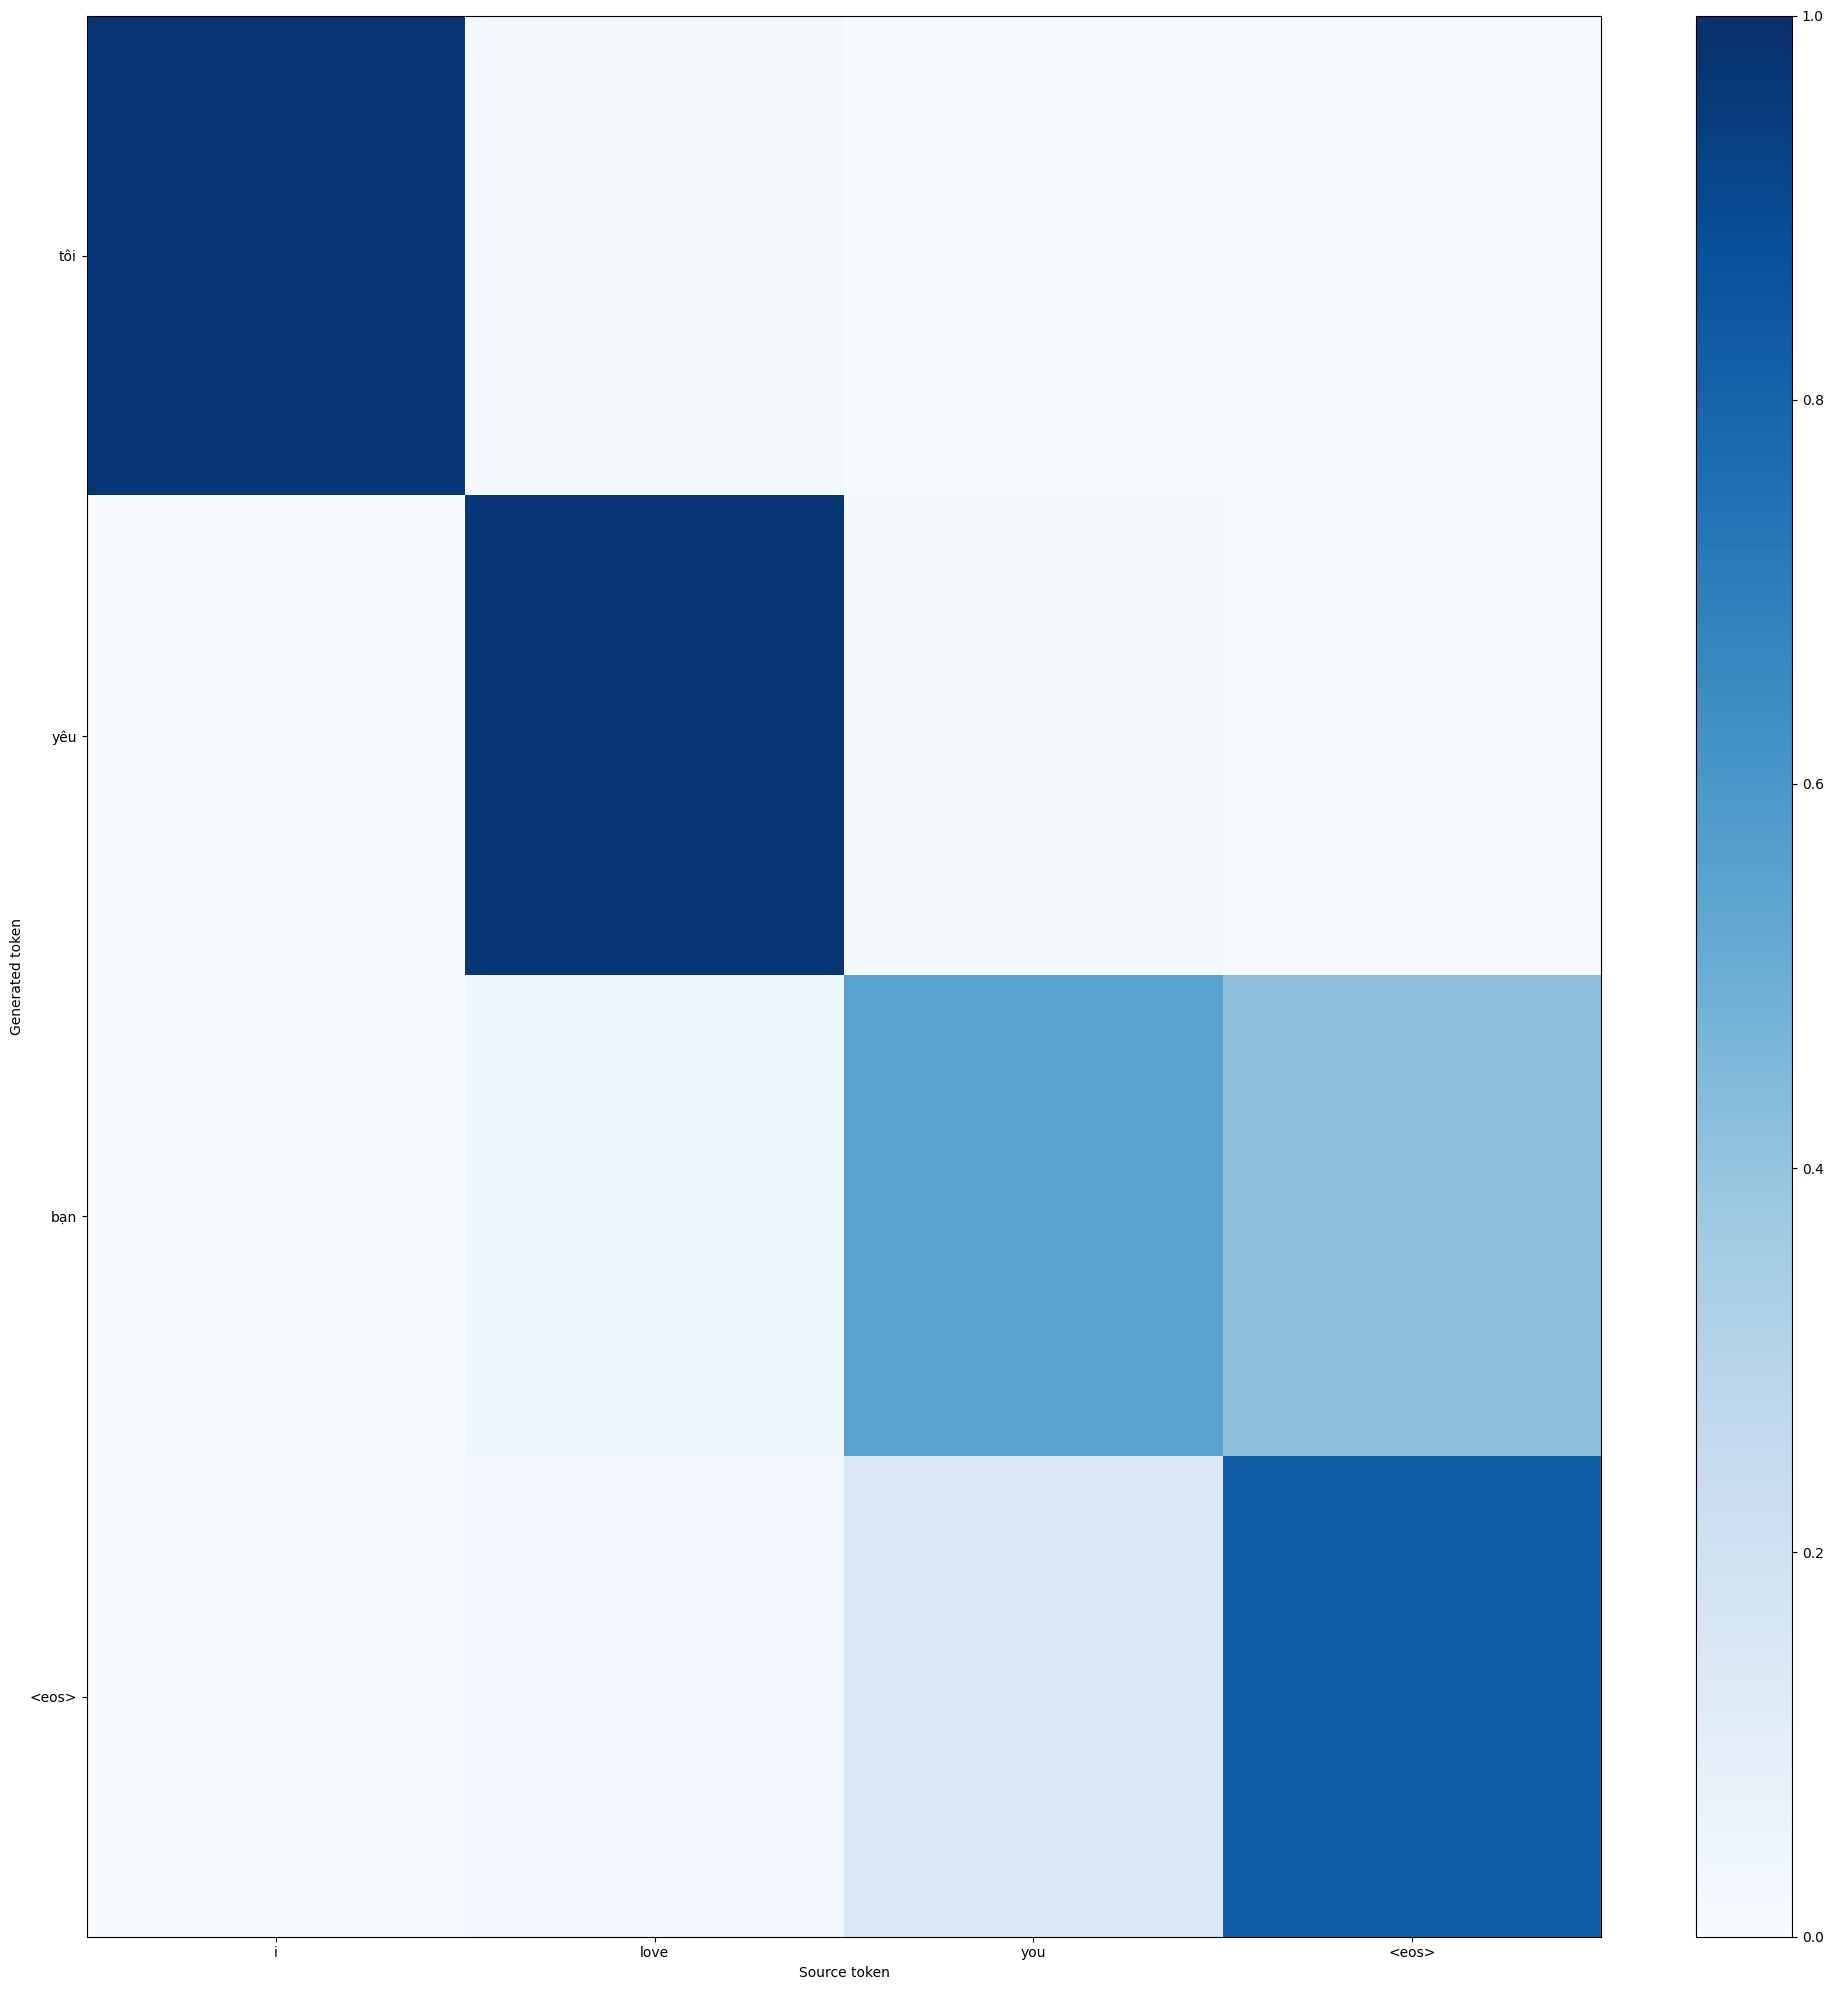

In [66]:
test_sentences=[45,6]
model_types=['none','bahdanau','luong']
for i in range(3):
    print('Ba câu mẫu và heatmap cho model Bài', i+1)
    model_type=model_types[i]
    model=models[model_type]
    for j in test_sentences:
        print('Original sentence:', filtered['test'][j]['src'])
        print('Actual translation:', filtered['test'][j]['tgt'])
        row = dict(id=-1, src=tokens(raw['test'][j]['english']), tgt=tokens(raw['test'][j]['vietnamese']))
        b = collate([row])
        src= b['src'].to(device)
        predicted, weights = generate(model, src, b['lengths'], 8)
        print('Generated translation:', decode(predicted[0].cpu()))
        if i>=1:
            shown_ids = predicted[0].cpu().tolist()
            stop = shown_ids.index(EOS)+1 if EOS in shown_ids else len(shown_ids)
            matrix = weights[0, :stop, :b['lengths'][0]].cpu().numpy()
            x_labels = row['src']+['<eos>']
            y_labels = [tgt_itos[i] for i in shown_ids[:stop]]
    # Vẽ heatmap: hàng là token sinh ra, cột là token nguồn
            fig, ax = plt.subplots(figsize=(20,20))
            image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
            ax.set_xticks(range(len(x_labels)), x_labels)
            ax.set_yticks(range(len(y_labels)), y_labels)
            ax.set_xlabel('Source token')
            ax.set_ylabel('Generated token')
            fig.colorbar(image, ax=ax)
            fig.tight_layout()
    #        fig.savefig(ART/'attention_toy.png', dpi=150)
            plt.show()
        print('\n')
    print('Original sentence: i love you')
    print('Actual translation: tôi yêu bạn')
    row = dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn'))
    b = collate([row])
    src= b['src'].to(device)
    predicted, weights = generate(model, src, b['lengths'], 8)
    print('Generated translation:', decode(predicted[0].cpu()))
    if i>=1:
        shown_ids = predicted[0].cpu().tolist()
        stop = shown_ids.index(EOS)+1 if EOS in shown_ids else len(shown_ids)
        matrix = weights[0, :stop, :b['lengths'][0]].cpu().numpy()
        x_labels = row['src']+['<eos>']
        y_labels = [tgt_itos[i] for i in shown_ids[:stop]]
# Vẽ heatmap: hàng là token sinh ra, cột là token nguồn
        fig, ax = plt.subplots(figsize=(20,20))
        image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        ax.set_xticks(range(len(x_labels)), x_labels)
        ax.set_yticks(range(len(y_labels)), y_labels)
        ax.set_xlabel('Source token')
        ax.set_ylabel('Generated token')
        fig.colorbar(image, ax=ax)
        fig.tight_layout()
#        fig.savefig(ART/'attention_toy.png', dpi=150)
        plt.show()
        print('\n')
    print('\n \n \n')